In [1]:
import os

import lifelines
import matplotlib.pyplot as plt
import matplotlib
import numpy
import pandas
import pickle
import time
import seaborn as sns

import immuw.clustering.clustering_utils as cimu
import cellohood_analysis_utils as tau


#matplotlib.font_manager.fontManager.addfont('/path/to/font/Arial.ttf')  # if you need to add the font file
#plt.rcParams['font.family'] = 'Arial'


# Number of enriched cellular neighborhood classes
CC_NB_OF_CLUSTERS = 7
ROI_TYPE_ANALYSIS = 'TUMOR'


ZENODO_PATH = '/raid/immucan/immuw/cellohood_artifacts/'
NSCLC_P1_ZENODO_PATH = os.path.join(ZENODO_PATH, 'NSCLC_P1')
NSCLC_P1_PLDA_1_PATH = os.path.join(NSCLC_P1_ZENODO_PATH, 'TUMOR_PLDA.1')


VECTORIZER = lambda x: x.values.T ** 0.5
PANEL_1_CLUSTER_SELECTION_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'p1_plda_1_cs_result.pickle')

# PREDICTION RELATED 
TYPE = 'sd'
PREDICTIONS_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'predictions.npy')
PREDICTION_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster'
CC_CLUSTER_NAME = 'tumorhood_neighborhood_cluster'

COUNT_CLUSTERER_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'count_clusterer.pickle')
SD_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'cells_with_sd.csv')

# IMAGE/SAMPLE RELATED 
ROI_COLUMN = 'image'
SAMPLE_COLUMN = 'sample_id'


CLINICAL_DATA_DF = os.path.join(NSCLC_P1_ZENODO_PATH, 'nsclc_clinical.csv')


PANEL_1_FULL_CSV_FILEPATH = os.path.join(NSCLC_P1_ZENODO_PATH, 'nsclc2_p1_25.df')

# MARKER RELATED
MARKERS = tau.PANEL_1_MARKER_NAMES
MARKERS_CLEAN = [
    'MPO',
    'H3',
    'SMA',
    'CD16',
    'CD38',
    'HLA-DR',
    'CD27',
    'CD15',
    'CD45RA',
    'CD163',
    'B2M',
    'CD20',
    'CD68',
    'Ido1',
    'CD3',
    'LAG3',
    'CD11c',
    'PD1',
    'PDGFRb',
    'CD7',
    'GrB',
    'PDL1',
    'TCF7',
    'CD45RO',
    'FOXP3',
    'ICOS',
    'CD8a',
    'CAIX',
    'CD33',
    'Ki67',
    'VISTA',
    'CD40',
    'CD4',
    'CD14',
    'ECad',
    'CD303',
    'CD206',
    'cl.PARP',
    'DNA1',
    'DNA2',
]

# Clinical Related:
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'roman_simple_stage', 
    'stage_2-',
    'simple_histology',
    'death', 
    'smoking_status',
    'gender',
    'TPS_score',
    'CPS_score',
    'tmb_class',
] 


CLASS_COLNAME = 'Class'

CELLTYPE_TO_CLASS = {
   'B': 'Immune',
   'BnT': 'Immune',
   'CD4': 'Immune',
   'CD8': 'Immune',
   'DC': 'Immune',
   'HLADR': 'Immune',
   'MacCD163': 'Immune',
   'Mural': 'Mural',
   'NK': 'Immune',
   'Neutrophil': 'Immune',
   'Treg': 'Immune',
   'Tumor': 'C.Tumor',
   'pDC': 'Immune',
   'plasma': 'Immune',
   'undefined': 'Other' 
}

# Additional Column names
DUMMY_COL_NAME = 'Dummy'
CELLTYPE_COLNAME = 'celltypes'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_CLUSTER_NAME = 'SG'

IMMUCAN_ID_COL = 'immucan_id'

# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

## Cell type level data loading and preprocessing

In [2]:
cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)

/tmp/ipykernel_1416863/796832730.py:1: DtypeWarning: Columns (15,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)


In [3]:
# Marker ARCSINH x / 5 transformation
cell_df[MARKERS] =  cell_df[MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [4]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [5]:
predictions = numpy.load(PREDICTIONS_PATH)

In [6]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## TLS / Tumor Core subselection

In [7]:
def roi_is_tls(image_name):
    return image_name[:-5].split('_')[-1] == '004'

In [8]:
TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: roi_is_tls(x))
NON_TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: not roi_is_tls(x))

In [9]:
if ROI_TYPE_ANALYSIS == 'TUMOR':
    cell_df = cell_df[NON_TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'TLS':
    cell_df = cell_df[TLS_CELL_SELECTOR]
else:
    raise ValueError('Unknown ROI type analysis')

## Cell type related preparation:

In [10]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [11]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [12]:
celltypes = list(celltype_percentages.columns)

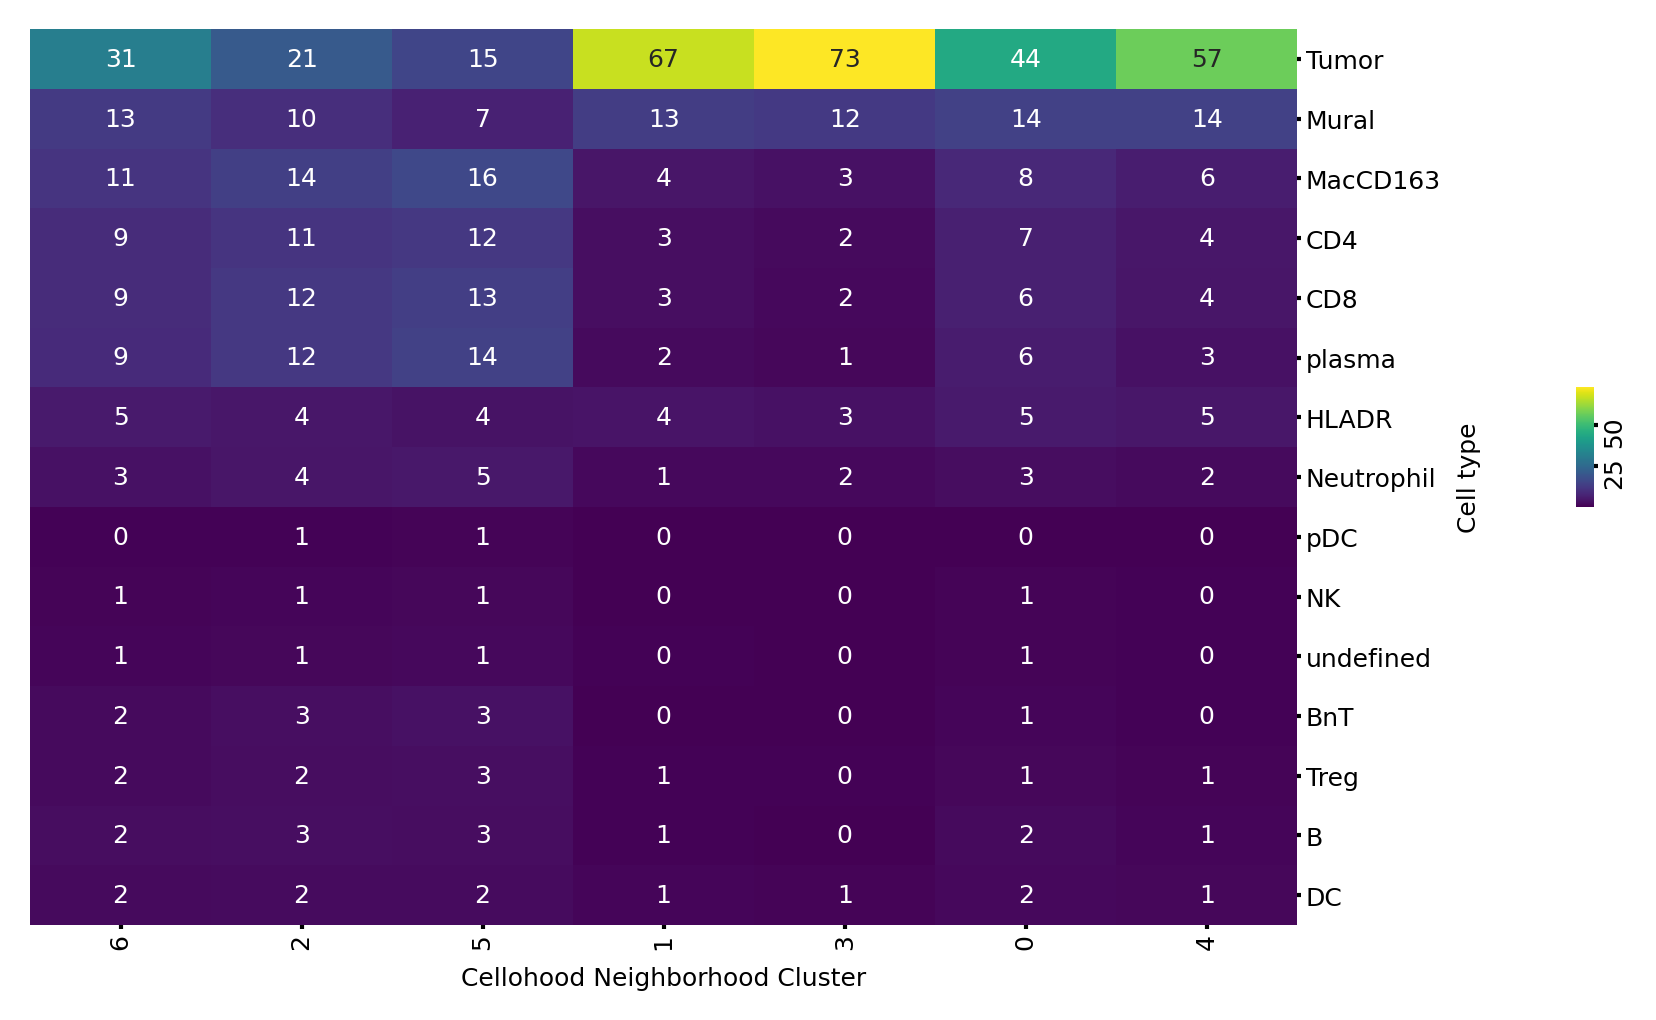

In [13]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Class Cell type related preparation:

In [14]:
cell_df[CLASS_COLNAME] = cell_df[CELLTYPE_COLNAME].apply(lambda x: CELLTYPE_TO_CLASS[x])

In [15]:
class_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CLASS_COLNAME],
    aggfunc="sum",
).fillna(0)

In [16]:
class_percentages = (class_counts.T / class_counts.sum(axis=1)).T

In [17]:
classes = list(class_percentages.columns)

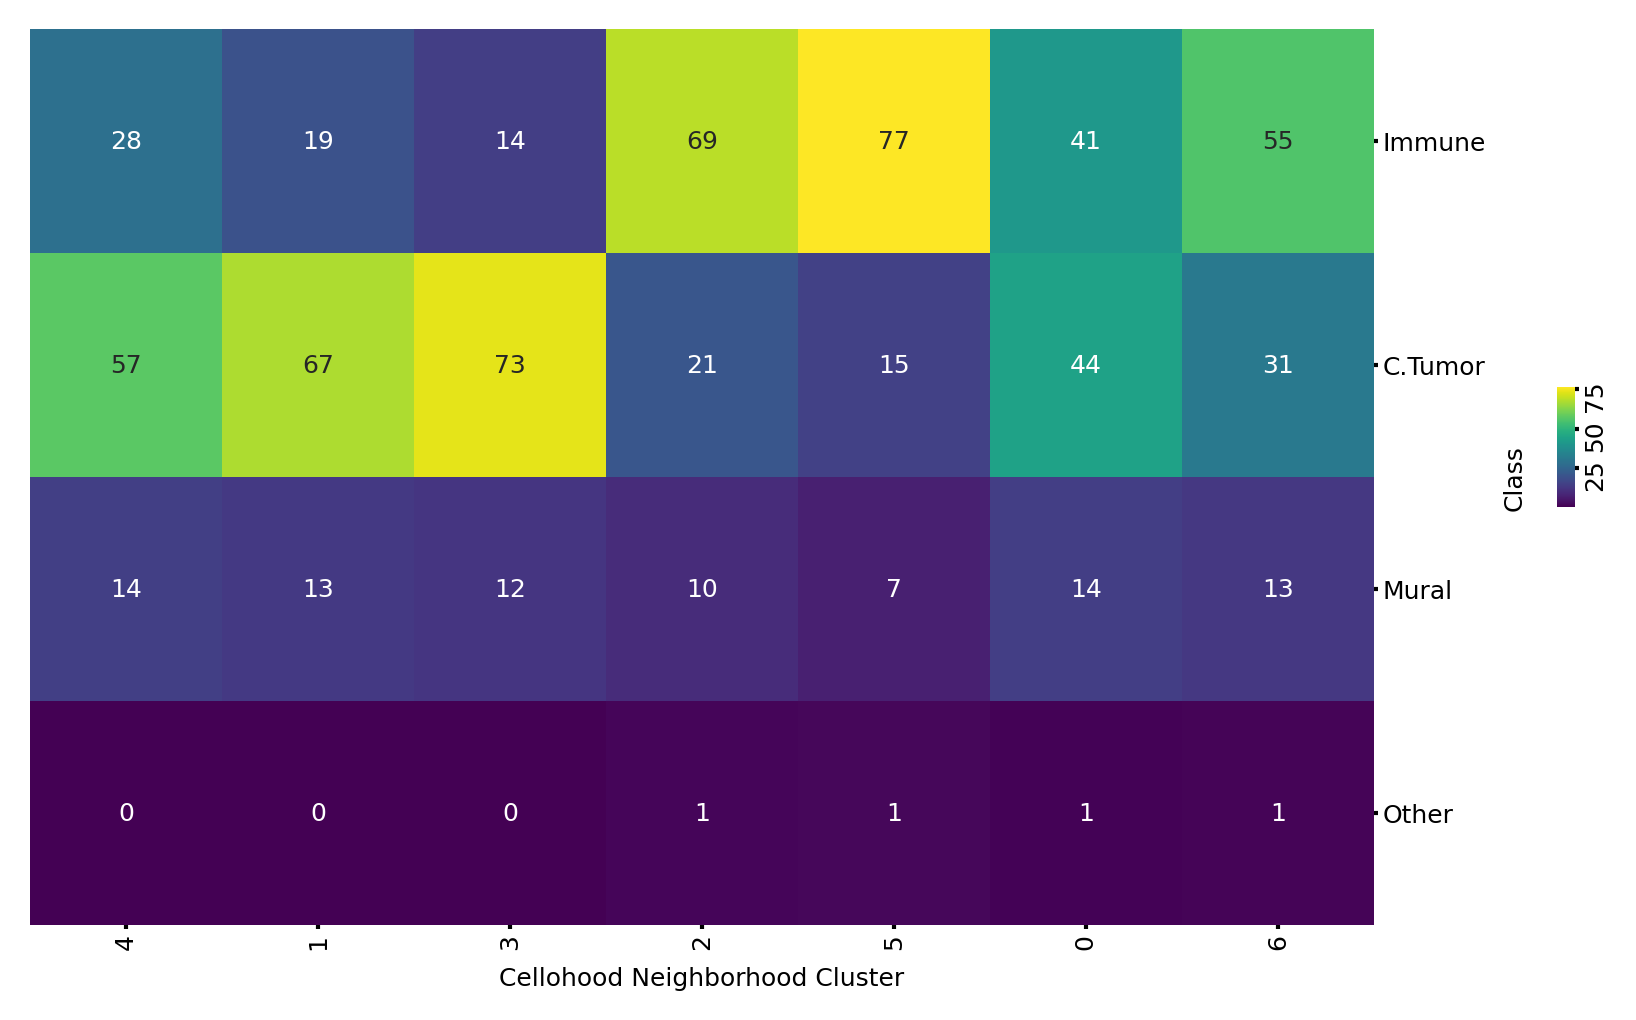

In [18]:
class_clustermap = sns.clustermap(
    class_percentages[classes].T * 100, 
    annot=True,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

class_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
class_clustermap.ax_row_dendrogram.set_visible(False)
class_clustermap.ax_col_dendrogram.set_visible(False)

class_clustermap.ax_heatmap.set_yticklabels(class_clustermap.ax_heatmap.get_yticklabels(), size=6)
class_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
class_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
class_clustermap.ax_heatmap.set_xticklabels(class_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


class_clustermap.fig.set_dpi(PLOTTING_DPI)
class_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [19]:
marker_to_celltype_dfs = {}


for marker in MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [20]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [21]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

### Class type level:

For each marker compute the average marker expression for a given class type:

In [22]:
marker_to_class_dfs = {}


for marker in MARKERS:
    marker_to_class_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CLASS_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to class to marker df:

In [23]:
marker_c_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_class_dfs.values()
])

class_to_marker_dfs = {
    c: pandas.DataFrame(
        marker_c_ipc[:, :, c_ind],
        index=MARKERS,
    )
    for c_ind, c in enumerate(classes)
}

Now - let's rename the markers to their clean names:

In [24]:
for class_, cdf in class_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[class_] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [25]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_1416863/762203048.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]


Now let's display the all marker distributions:

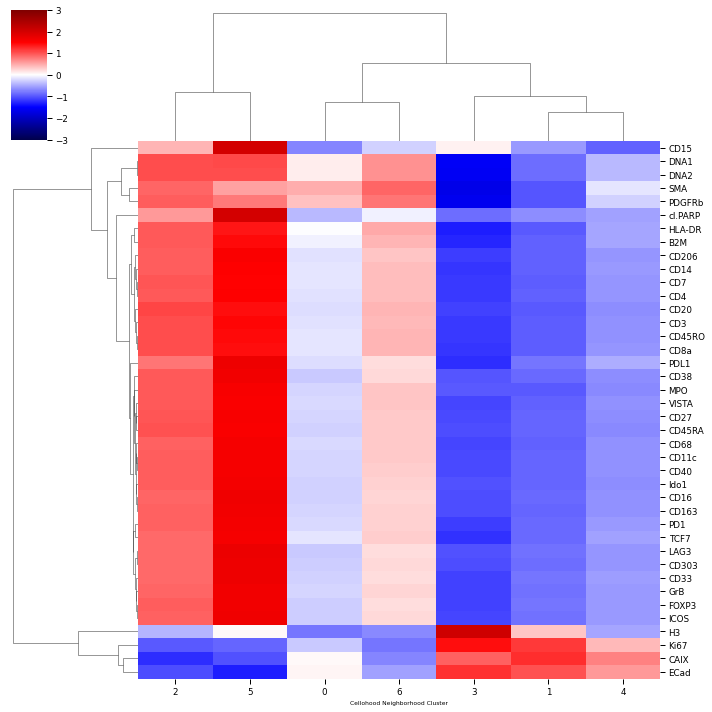

In [26]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [27]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [28]:
IGNORE_COLOR = (160 / 255, 160 / 255, 160 / 255)


def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=IGNORE_COLOR,
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [29]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

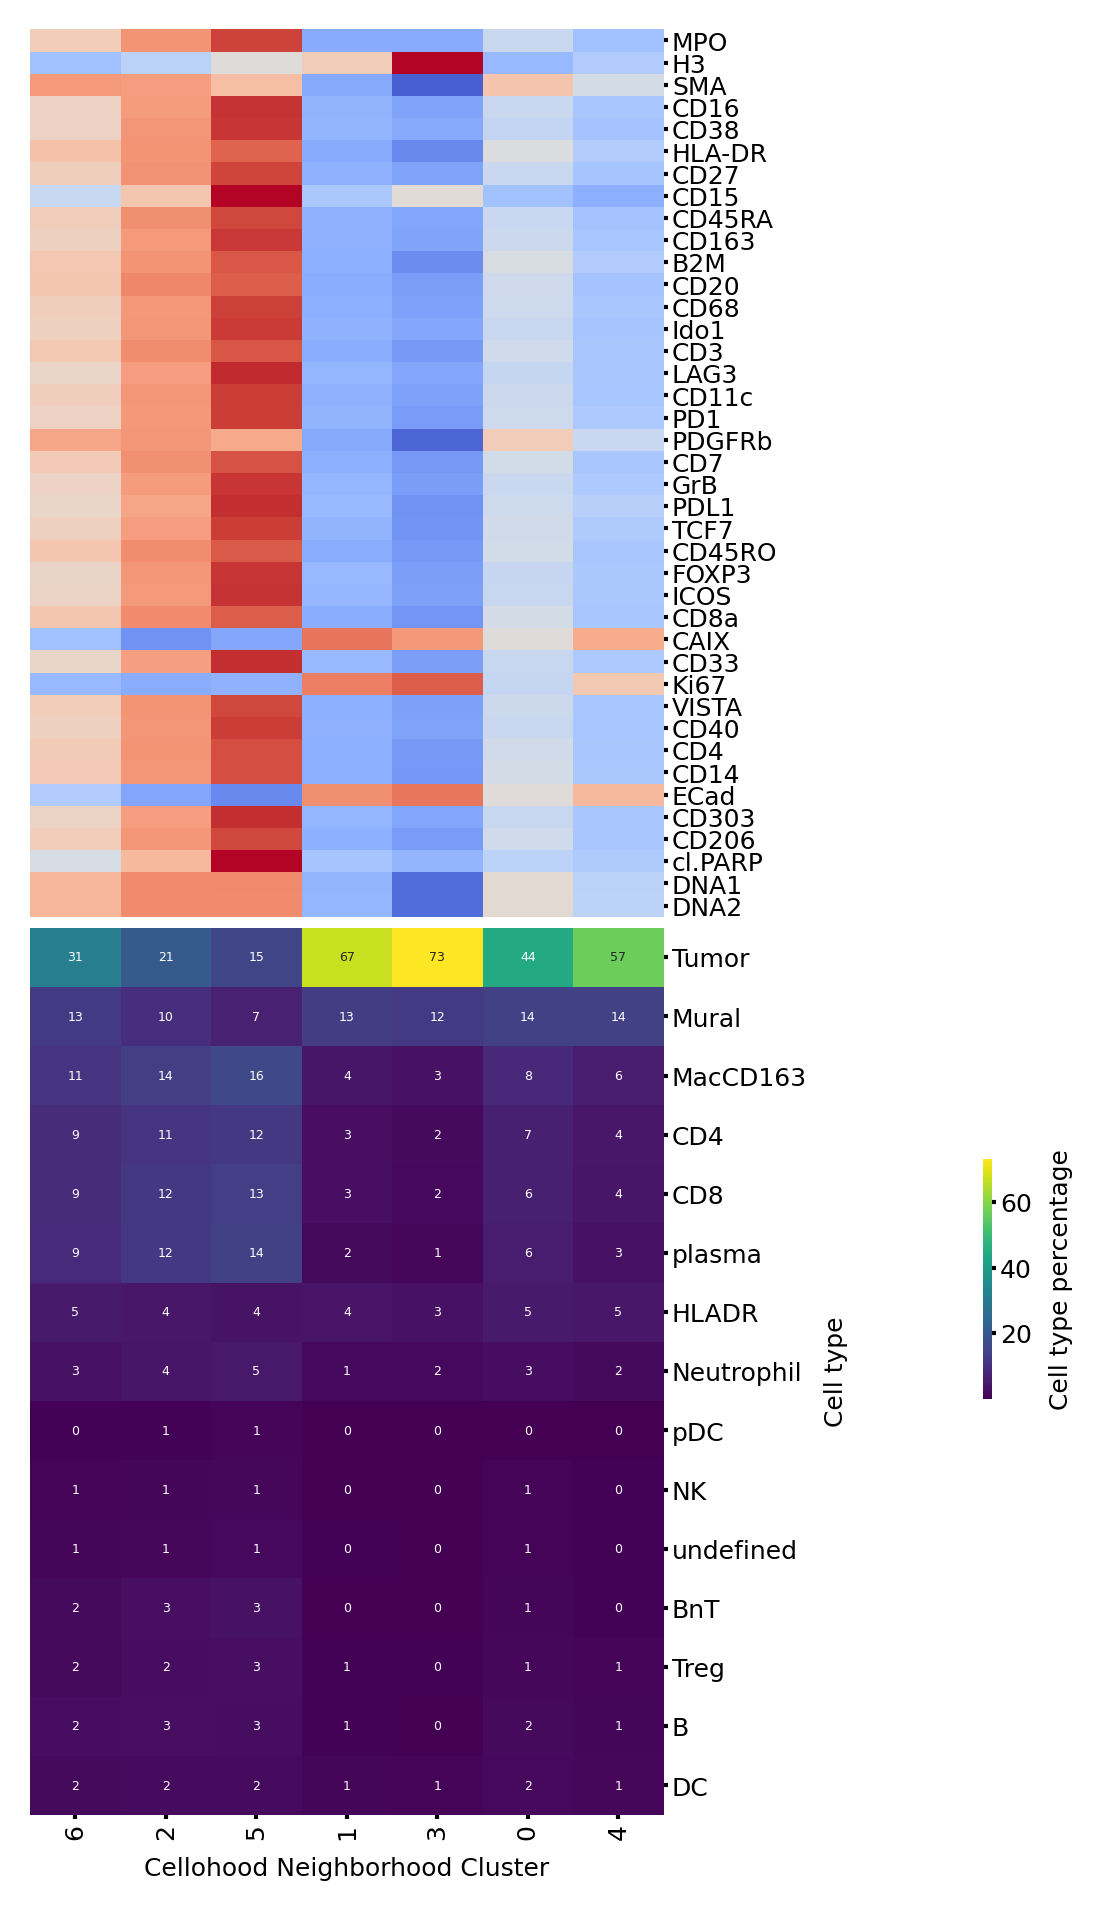

In [30]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Density analysis

In [31]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [32]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

Now, let's clinical data:

In [33]:
clinical_data_df = pandas.read_csv(CLINICAL_DATA_DF)
clinical_data_df['is_squamous'] = clinical_data_df['simple_histology'].apply(lambda x: 'squamous' in x.lower())

In [34]:
image_to_sample = cell_df.groupby(ROI_COLUMN)[SAMPLE_COLUMN].first()

In [35]:
roi_counts[ROI_COLUMN] = roi_counts.index

In [36]:
roi_counts[IMMUCAN_ID_COL] = roi_counts[ROI_COLUMN].apply(lambda x: image_to_sample[x])
roi_counts[IMMUCAN_ID_COL] = roi_counts[IMMUCAN_ID_COL].apply(
    lambda x: '-'.join(x.split('-')[:3])
)

In [37]:
roi_counts = pandas.merge(clinical_data_df, roi_counts, on=IMMUCAN_ID_COL)

In [38]:
roi_counts['patient'] = roi_counts[IMMUCAN_ID_COL]

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [39]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

/tmp/ipykernel_1416863/2527830171.py:34: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.4, 2.4])

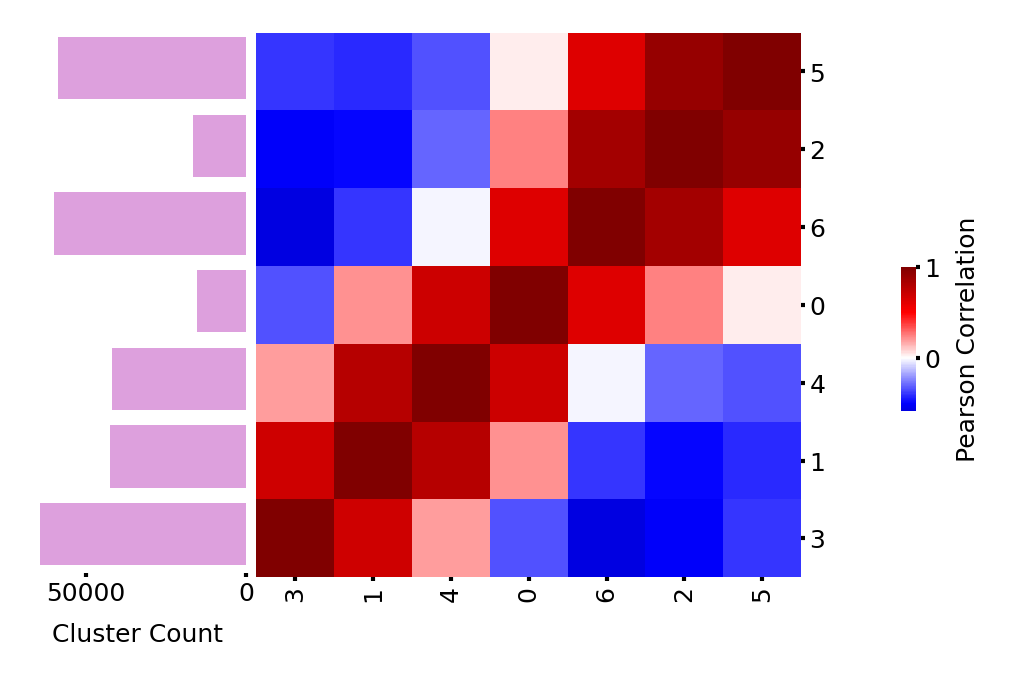

In [40]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    cbar_pos=[1.1, 0.27, 0.02, 0.2],
    cbar_kws={'label': 'Pearson Correlation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Cluster Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.4, 2.4))
plt.gcf().get_size_inches()

and let us have a look at found cluster numbers:

In [41]:
import joblib


clusterer = joblib.load(COUNT_CLUSTERER_PATH)
vectors = VECTORIZER(roi_counts[list(range(CC_NB_OF_CLUSTERS))])
clusters = clusterer.predict(vectors.T)

## Patient Clustermap

In [42]:
ROI_CLUSTERS = 3

In [43]:
from collections import defaultdict

import matplotlib.colors as mpc


hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}


tmb_colors_dict = defaultdict(lambda: mpc.TABLEAU_COLORS['tab:cyan'])
tmb_colors_dict['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_colors_dict['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_colors_dict['<0.1'] = mpc.CSS4_COLORS['limegreen']

In [44]:
UNK_COLOR = mpc.CSS4_COLORS['lightgrey']

HISTOLOGY_PLOT_NAME = 'Histology'
STAGE_PLOT_NAME = 'Stage'
TMB_PLOT_NAME = 'TMB'
DEATH_PLOT_NAME = 'Death'
CPS_PLOT_NAME = 'CPS'
TPS_PLOT_NAME = 'TPS'
NEO_PLOT_NAME = 'Neo-adjuv.'
GENDER_PLOT_NAME = 'Gender'
SMOKING_PLOT_NAME = 'Smoking'

# Genes
KRAS_PLOT_NAME = 'GM: KRAS'
TP53_PLOT_NAME = 'GM: TP53'
EGFR_PLOT_NAME = 'GM: EGFR'
PIK3CA_PLOT_NAME = 'GM: PIK3CA'
ERBB2_PLOT_NAME = 'GM: ERBB2'

In [45]:
patient_to_clinical_colors_dict = {}

# Histology
patient_to_clinical_colors_dict[HISTOLOGY_PLOT_NAME] = [
    tau.SIMPLE_HISTOLOGY_COLORS[hist] for hist in roi_counts['simple_histology']
]

# Stage
patient_to_clinical_colors_dict[STAGE_PLOT_NAME] = [
    tau.SIMPLE_STAGE_COLORS[st] for st in roi_counts['simple_stage']
]

# TMB
tmb_color = defaultdict(lambda: UNK_COLOR)
tmb_color['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_color['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_color['<0.1'] = mpc.CSS4_COLORS['limegreen']
patient_to_clinical_colors_dict[TMB_PLOT_NAME] = [
    tmb_color[st] for st in roi_counts['tmb_class']
]

# Death
death_color = defaultdict(lambda: UNK_COLOR)
death_color[True] = mpc.CSS4_COLORS['red']
death_color[False] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[DEATH_PLOT_NAME] = [
    death_color[st] for st in roi_counts['death']
]

# CPS
cps_color = defaultdict(lambda: UNK_COLOR)
cps_color['positive'] = mpc.CSS4_COLORS['blue']
cps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[CPS_PLOT_NAME] = [
    cps_color[st] for st in roi_counts['CPS_score']
]

# TPS
tps_color = defaultdict(lambda: UNK_COLOR)
tps_color['positive'] = mpc.CSS4_COLORS['blue']
tps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[TPS_PLOT_NAME] = [
    tps_color[st] for st in roi_counts['TPS_score']
]


# gender 
neo_color = defaultdict(lambda: UNK_COLOR)
neo_color['Male'] = mpc.CSS4_COLORS['blue']
neo_color['Female'] = mpc.CSS4_COLORS['red']
patient_to_clinical_colors_dict[GENDER_PLOT_NAME] = [
    neo_color[st] for st in roi_counts['gender']
]


smoking_colors = {
    'Ex-smoker': '#d95f02',      # Orange
    'Current smoker': '#7570b3',  # Purple
    'Non-smoker': '#1b9e77'      # Green-blue
}


patient_to_clinical_colors_dict[SMOKING_PLOT_NAME] = [
    smoking_colors[x] for x in roi_counts['smoking_status']
]

patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)

In [46]:
clusters_mapping = {
    0: 0,
    1: 2,
    2: 1,
}

In [47]:
centers = []
bars = [0]
aux = 0


for cl_ in range(ROI_CLUSTERS):
    current_cluster_count = (clusters == clusters_mapping[cl_]).sum()
    centers.append(aux + current_cluster_count // 2)
    aux += current_cluster_count
    bars.append(aux - 1)

    
ticks = []
current_cluster = 0

for i in range(len(clusters)):
    if i in centers:
        ticks.append(clusters_mapping[current_cluster])
        current_cluster += 1
        continue
    elif i in bars:
        ticks.append('|')
        continue
    else:
        ticks.append('')
        

In [48]:
horizontal_ticks = [
    str(tick).replace('|', '|') 
    for tick in ticks
]

In [49]:
clusters_mapping = {
    0: 0,
    1: 2,
    2: 1,
}

In [50]:
tumor_percentage = -celltype_percentages['Tumor']


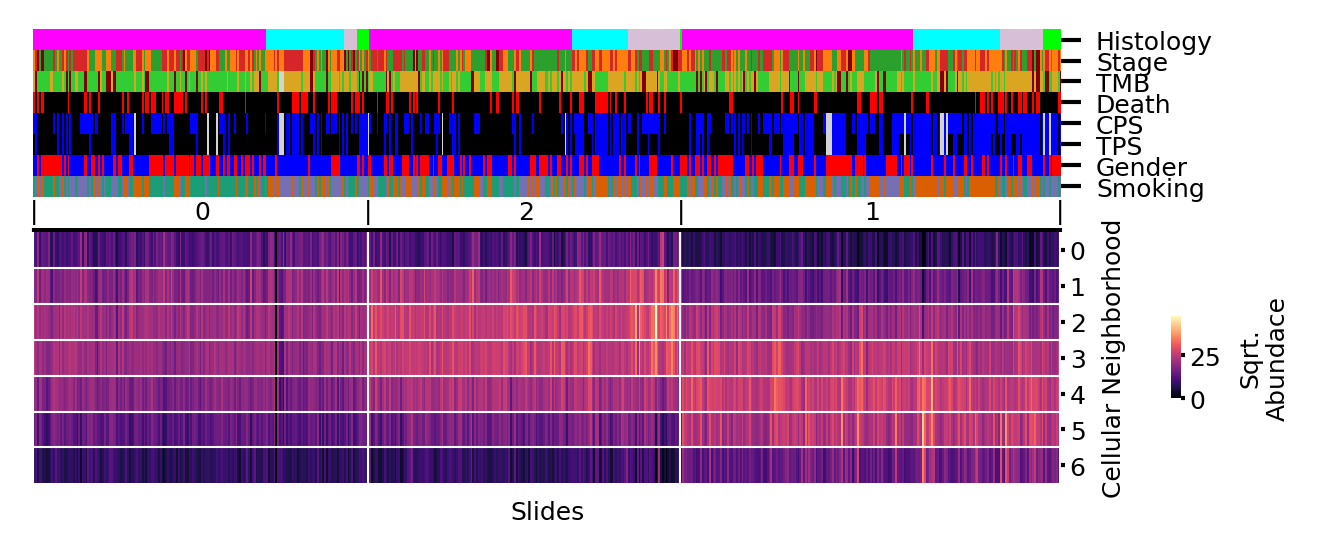

In [51]:
# plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
vectors_df.index.name = 'Slides'
vectors_df.columns.name = 'Cellular Neighborhood'


#patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * clusters_mapping[cl] + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[
        clusters_with_histology.argsort()].T.iloc[tumor_percentage.values.argsort()],
    col_cluster=False,
    row_cluster=False,
    cbar_pos=[.97, 0.23, 0.007, .14],
    cbar_kws={'label': 'Sqrt.\nAbundace'},
    xticklabels=horizontal_ticks,
    yticklabels=list(range(7)),
    col_colors=patient_to_clinical_colors_df,
    figsize=(8, 6),
    colors_ratio=0.04,
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=0)


patient_clustermap.ax_col_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_col_colors.set_yticklabels(
    patient_clustermap.ax_col_colors.get_yticklabels(), size=6,
)
patient_clustermap.ax_col_colors.xaxis.tick_top()

ax_col_colors = patient_clustermap.ax_col_colors
col_box = ax_col_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.max[1] + 0.06, col_box.width, col_box.height])

patient_clustermap.ax_heatmap.xaxis.tick_top()

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((4.9, 1.965))

for i in range(1, 7):
    patient_clustermap.ax_heatmap.hlines(i, 0, vectors_df.shape[0], linewidth=0.5, color="white")
    
for bar in bars:
    patient_clustermap.ax_heatmap.vlines(bar, 0, 7, linewidth=0.5, color="white")

## Clinical Data analysis

In [52]:
roi_counts[DUMMY_COL_NAME] = 1
roi_counts[ROI_CLUSTER_NAME] = clusters

In [53]:
roi_cluster_counts = pandas.pivot_table(
    roi_counts, 
    values=DUMMY_COL_NAME, 
    index=[IMMUCAN_ID_COL],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0) > 0

In [54]:
ROI_CLUSTER_NAMES = [f'{ROI_CLUSTER_NAME}: {cl_}' for cl_ in roi_cluster_counts.columns]

ROI_CLUSTER_INDICES = list(roi_cluster_counts.columns)
roi_cluster_counts.columns = ROI_CLUSTER_NAMES
roi_cluster_counts.index.name = IMMUCAN_ID_COL

In [55]:
roi_cluster_with_clinical = pandas.merge(roi_cluster_counts, clinical_data_df, on=IMMUCAN_ID_COL)

Now, let's filter out patients with percentage lower than `0.04`.

In [56]:
PERCENTAGE_TO_FILTER_OUT = 0.04

GOOD_ROI_CLUSTERS = [
    cl 
    for cl, row in roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows()
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]


GOOD_ROI_CLUSTERS_INDS = [
    row_nb 
    for row_nb, (cl, row) in enumerate(roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows())
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]

Now, let us compute a table with enrichements scores for clusters and clinical features, for subgroups of patients that have a particular ROI cluster:

In [57]:
import matplotlib.pyplot as plt


roi_pval_table = pandas.concat(
    [
        pandas.concat(
            [
                tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=roi_cluster_with_clinical[cluster] > 0,
                    column=column,
                    values=None,
                    filter_nas=True,
            ).iloc[[1]]
            for column in CLINICAL_DATA_COLS_FOR_ANALYSIS],
            axis=1,
        )
        for cluster in GOOD_ROI_CLUSTERS
    ],
    axis=0,
)

roi_pval_table.index = [
    f'{cluster}'
    for cluster in GOOD_ROI_CLUSTERS
]

Now, let's compute the FDR corrected p-values:

In [58]:
roi_qval_table = tau.apply_fdr_to_df(roi_pval_table)

Now, let's clean out the names of the clinical features:

In [59]:
raw_clinical_to_clean_clinical_names = {
    'smoking_status: ': '',
    '_score:': ':',
    'positive': 'Positive',
    'negative': 'Negative',
    'roman_simple_stage': 'TNM',
    'simple_histology': 'Histology',
    'tmb_class': 'TMB',
    'stage_2-: False': 'TNM: III, IV',
    'stage_2-: True': 'TNM: I, II',
    'neo_adjuvant_treatment:': 'NeoAdj. Treat.:',
    'gender: ': '',
    'environmental_exposure': 'Env. Exposure',
    'Histology': 'Hist',
    'Adenosquamous carcinoma': 'Adeno-sq.',
    'KRAS': 'GM: KRAS',
    'PIK3CA': 'GM: PIK3CA',
    'EGFR': 'GM: EGFR',
    'TP53': 'GM: TP53',
    'ERBB2': 'GM: ERBB2',
    'death: 1': 'Death: True',
}

def clean_clinical_name(name, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = raw_clinical_to_clean_clinical_names
    for raw_name, clean_name in replacement_dict.items():
        name = name.replace(raw_name, clean_name)
    return name

In [60]:
roi_qval_table.columns = [clean_clinical_name(col) for col in roi_qval_table.columns]

Now, let's filter out the cases with `FDR_ALPHA` and lower scores:

In [61]:
FDR_ALPHA = 0.2

q_vals_sig_series = roi_qval_table.min() < FDR_ALPHA

sl_qvals_text = roi_qval_table.copy()
sl_qvals_text = sl_qvals_text.applymap(lambda x: str(round(x, 2)) if x < FDR_ALPHA  else '')

<Figure size 3600x2400 with 0 Axes>

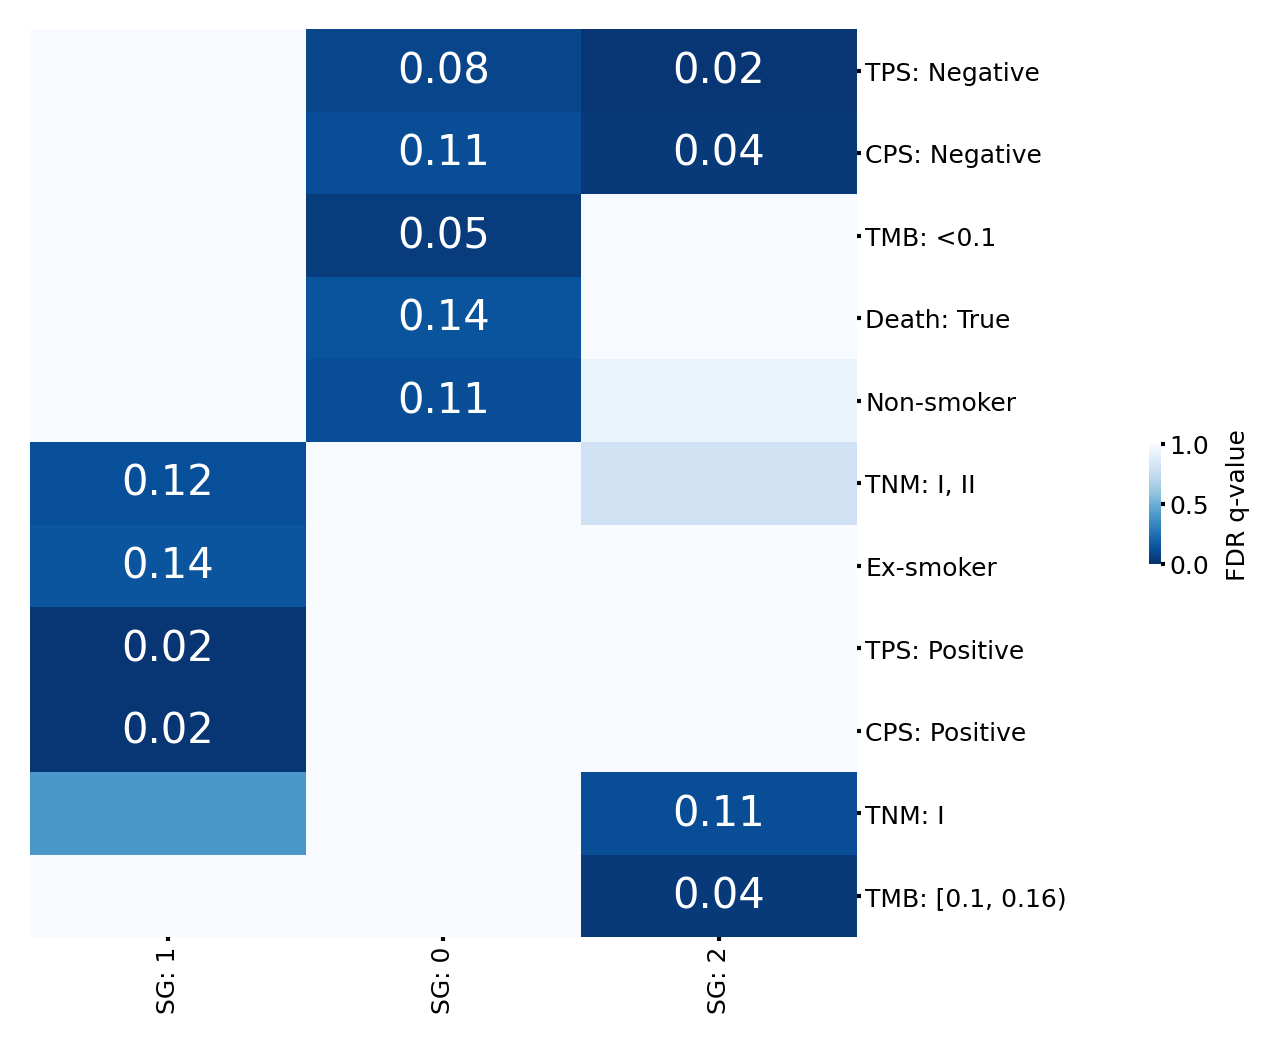

In [62]:
plt.figure(dpi=600)

clinical_cm = sns.clustermap(
    roi_qval_table.T[q_vals_sig_series], 
    cmap='Blues_r', 
    annot=sl_qvals_text.T[q_vals_sig_series], 
    yticklabels=sl_qvals_text.T[q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'FDR q-value'},
)
clinical_cm.ax_cbar.set_visible('False')
clinical_cm.ax_heatmap.xaxis.set_tick_params(rotation=0)

clinical_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clinical_cm.ax_row_dendrogram.set_visible(False)
clinical_cm.ax_col_dendrogram.set_visible(False)

clinical_cm.ax_heatmap.set_yticklabels(
    clinical_cm.ax_heatmap.get_yticklabels(), size=6
)
clinical_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clinical_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clinical_cm.ax_heatmap.set_xticklabels(
    clinical_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

clinical_cm.fig.set_dpi(PLOTTING_DPI)
clinical_cm.fig.set_size_inches((4, 4))

Now, let's prepare a colored version of the above table:

In [63]:
clinical_norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = matplotlib.cm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

clinical_colors = clinical_cm.data2d.applymap(lambda x: clinical_sm.to_rgba(x))

## Survival analysis:


### CC Cluster analysis:

In [64]:
def rename_cox_summary_index(index_, prefix='ROI', simple_stage_name='Grade'):
    new_index = []
    for el in index_:
        el = el.replace('is_squamous', 'Squam.')
        el = el.replace('is_adeno', 'Adeno')
        if el.startswith('pl'):
            new_index.append(f'{prefix}: {el.split("_")[-1]}')
            continue
        if el.startswith('simple_stage'):
            new_index.append(f'{simple_stage_name}: {el.split("_")[-1]}')
            continue
        new_index.append(el)    
    return new_index
        

### ROI Cluster Analysis

In [65]:
additional_feature_columns = ('is_adeno', 'is_squamous')


survival_df = pandas.DataFrame(
       {
            **{
                'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
                'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
                'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
            },
           **{
               col: roi_cluster_with_clinical[col]
               for col in additional_feature_columns
           },
            **{
                f'simple_stage_{i}': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i
                for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
            },
            **{
                f'pl_{ROI_CLUSTERS}_{int(i)}': roi_cluster_with_clinical[f'SG: {i}']
                for i in GOOD_ROI_CLUSTERS_INDS
            },
        }
    )

In [66]:
PRESENTATION_TICKS = ['Adeno', 'Squam.', 'Stage: 2', 'Stage: 3', 'Inflamed', 'St. Inf.', 'Stage: 4', 'Cold']

/tmp/ipykernel_1416863/2526273263.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox PH Model\nfor ROI Clusters')

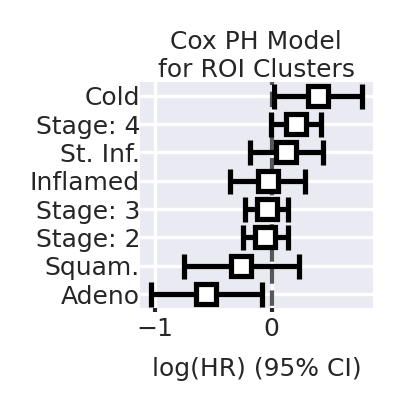

In [67]:
l2_true_value = 1e-3
l1_true_value = 0

coxphf_penalizer = l1_true_value + l2_true_value
coxphf_l1 = l1_true_value / (l1_true_value + l2_true_value)


roi_cox = tau.surivial_on_df(
    survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_1'},
)

plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1, 1), dpi=300)
cox_ax = roi_cox.plot()
yticklabels = [el.get_text() for el in cox_ax.get_yticklabels()]
new_ticks = rename_cox_summary_index(yticklabels, prefix='ROI', simple_stage_name='Stage')
_ = cox_ax.set_yticklabels(PRESENTATION_TICKS, size=6)

cox_ax.yaxis.set_tick_params(pad=1, size=1)
_ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)
cox_ax.xaxis.set_tick_params(pad=1, size=1)
cox_ax.yaxis.set_tick_params(pad=0, size=0)
cox_ax.set_ylim([-0.5, 7.5])

cox_ax.set_title('Cox PH Model\nfor ROI Clusters', fontsize=6, pad=1)

## Kaplan-Meier Curves:

### Clinical type vs ROI

/tmp/ipykernel_1416863/3348114586.py:46: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  handles = leg.legendHandles


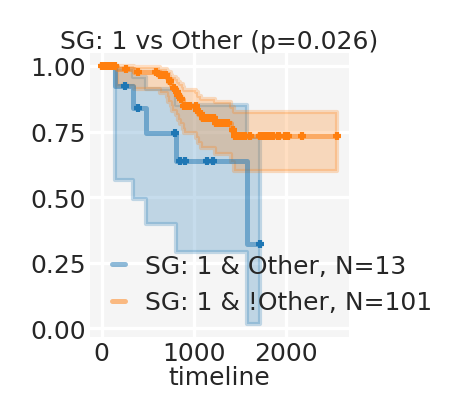

In [68]:
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


ct_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(CLINICAL_TYPES)))



for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(CLINICAL_TYPES):
        l_current_df = current_df[current_df['simple_histology'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_histology'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & {r_roi_cc}, N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'{l_roi_cc} vs {r_roi_cc} (p={round(ct_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.set_xlabel('timeline', labelpad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

            # Remove old legend
            leg.remove()

            # Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
            ax.grid(color='white', gapcolor='gray')
            plt.tight_layout()
            plt.show()

In [69]:
ct_vs_cluster_log_rank_pvalues_df = pandas.DataFrame(
    ct_vs_cluster_log_rank_pvalues,
    index=GOOD_ROI_CLUSTERS,
    columns=CLINICAL_TYPES,
)
ct_vs_cluster_log_rank_pvalues_df.index.name = f'{ROI_COLUMN} Clusters'
ct_vs_cluster_log_rank_pvalues_df.columns.name = f'Clinical Type'

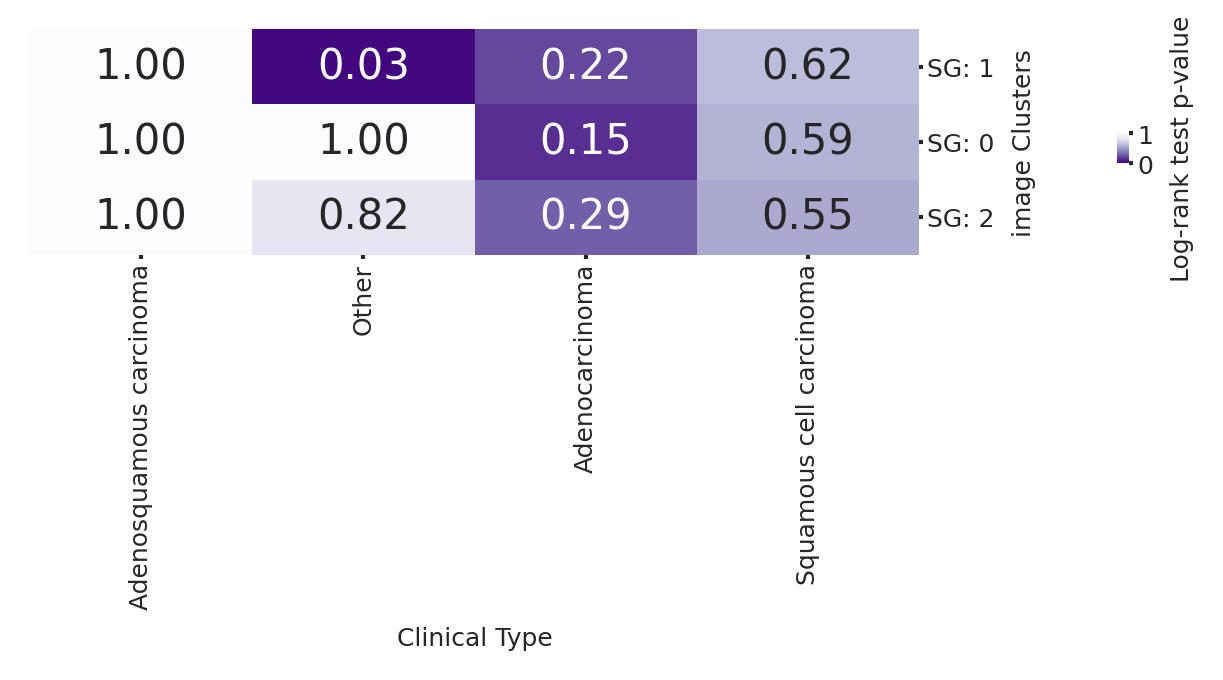

In [70]:
ct_vs_clusterlog_rank_cmap = sns.clustermap(
    ct_vs_cluster_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

ct_vs_clusterlog_rank_cmap.ax_cbar.set_visible('False')
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

ct_vs_clusterlog_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
ct_vs_clusterlog_rank_cmap.ax_row_dendrogram.set_visible(False)
ct_vs_clusterlog_rank_cmap.ax_col_dendrogram.set_visible(False)

ct_vs_clusterlog_rank_cmap.ax_heatmap.set_yticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
ct_vs_clusterlog_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
ct_vs_clusterlog_rank_cmap.ax_heatmap.set_xticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

ct_vs_clusterlog_rank_cmap.fig.set_dpi(PLOTTING_DPI)
ct_vs_clusterlog_rank_cmap.fig.set_size_inches((4, 1))

## Grade vs ROI

In [71]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GRADES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(GRADES):
        l_current_df = current_df[current_df['simple_stage'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_stage'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

/tmp/ipykernel_1416863/4086837001.py:48: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  handles = leg.legendHandles


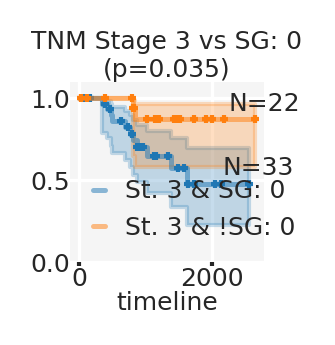

In [72]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GRADES), len(GOOD_ROI_CLUSTERS)))



for l_ind, l_roi_cc in enumerate(GRADES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.2, 1.25), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'St. {l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'St. {l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'TNM Stage {l_roi_cc} vs {r_roi_cc}\n(p={round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.xaxis.set_tick_params(size=1, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles
            l_x = ax.get_children()[1].get_xdata()[-1]
            l_y = ax.get_children()[1].get_ydata()[-1]
            plt.text(l_x - 400, l_y + 0.05, f'N={l_N}', size=6)
            leg = plt.gca().get_legend()
            r_x = ax.get_children()[3].get_xdata()[-1]
            r_y = ax.get_children()[3].get_ydata()[-1]
            plt.text(r_x - 400, r_y + 0.05, f'N={r_N}', size=6)

            # Remove old legend
            leg.remove()

            # Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
            plt.tight_layout()
            plt.show()

In [73]:
stage_1 = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == 1]
stage_2 = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == 2]
stage_4 = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == 4]
stage_3 = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == 3]
stage_3_0 = stage_3[stage_3['SG: 0'] == 1]
stage_3_n0 = stage_3[stage_3['SG: 0'] != 1]

In [74]:
tables = [stage_1, stage_2, stage_3, stage_4, stage_3_0, stage_3_n0]
names = ['Stage 1', 'Stage 2', 'Stage 3', 'Stage 4', 'Stage 3 w ROI:0', 'Stage 3 wo ROI:0']


stage_p_vals = numpy.ones((len(tables), len(tables)))
for lt_ind, lt in enumerate(tables):
    for rt_ind, rt in enumerate(tables):
        current_test = lifelines.statistics.logrank_test(
            lt['days_to_death'], rt['days_to_death'],
            lt['death'], rt['death'],
        )
        stage_p_vals[lt_ind, rt_ind] = current_test.p_value

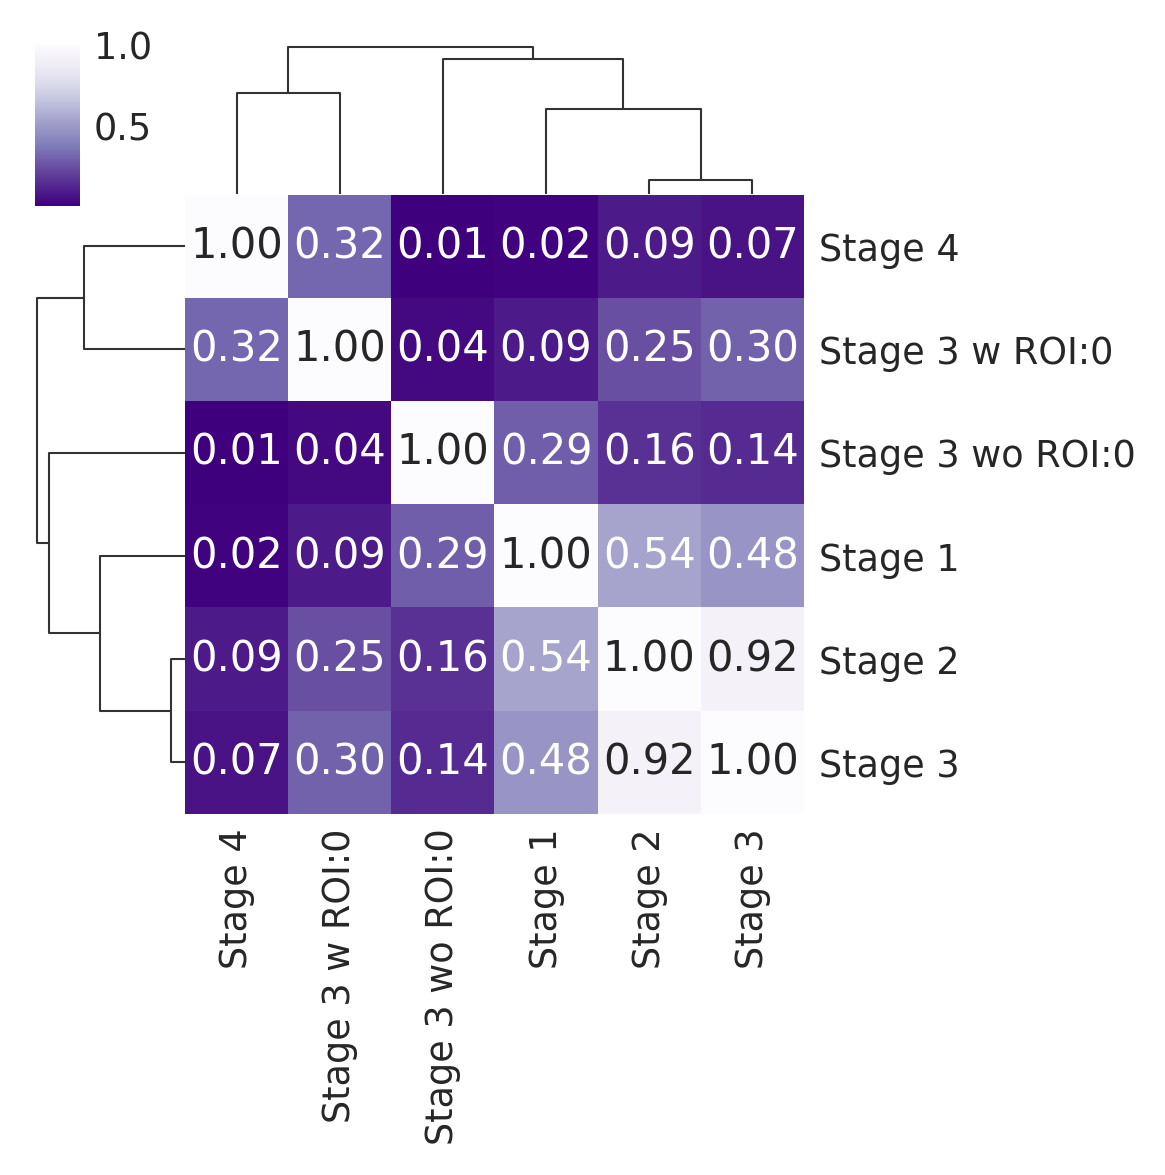

In [75]:
stages_cmap = sns.clustermap(
    stage_p_vals, 
    annot=True, 
    fmt='.2f', 
    xticklabels=names, 
    yticklabels=names,
    cmap='Purples_r'
    
)

stages_cmap.ax_heatmap.xaxis.set_tick_params(rotation=90)
stages_cmap.ax_heatmap.yaxis.set_tick_params(rotation=0)

stages_cmap.fig.set_dpi(PLOTTING_DPI)
stages_cmap.fig.set_size_inches((3, 3))

<Axes: xlabel='timeline'>

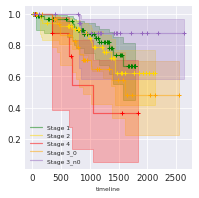

In [76]:
plt.figure(figsize=(3, 3))
s1_kmf = lifelines.KaplanMeierFitter(label=f'Stage 1')
s1_kmf.fit(stage_1['days_to_death'], stage_1['death'])
s1_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 4, 'linewidth': 0.5},  c='green')
s2_kmf = lifelines.KaplanMeierFitter(label=f'Stage 2')
s2_kmf.fit(stage_2['days_to_death'], stage_2['death'])
s2_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 4, 'linewidth': 0.5}, c='gold')
s4_kmf = lifelines.KaplanMeierFitter(label=f'Stage 4')
s4_kmf.fit(stage_4['days_to_death'], stage_4['death'])
s4_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 4, 'linewidth': 0.5}, c='red')
s3_0_kmf = lifelines.KaplanMeierFitter(label=f'Stage 3_0')
s3_0_kmf.fit(stage_3_0['days_to_death'], stage_3_0['death'])
s3_0_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 4, 'linewidth': 0.5}, c='orange')
s3_n0_kmf = lifelines.KaplanMeierFitter(label=f'Stage 3_n0')
s3_n0_kmf.fit(stage_3_n0['days_to_death'], stage_3_n0['death'])
s3_n0_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 4, 'linewidth': 0.5})

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [77]:
class_display_percentage = defaultdict(lambda: 0.05)
class_display_percentage['C.Tumor'] = 0.15
class_display_percentage['Mural'] = 0.10

In [78]:
class_to_marker_to_show = {
    'Immune': ['PD1', 'PDL1', 'GrB', 'B2M'],
    'Mural': ['SMA', 'PDGFRb'],
    'C.Tumor': ['DNA1', 'H3', 'ECad', 'cl.PARP', 'CAIX', 'PDL1', 'Ki67', 'B2M'],
}

In [79]:
class_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(class_percentages[ct] > class_display_percentage[ct])
        if cc_
    ]
    for ct in class_to_marker_to_show
}

In [80]:
cc_colors_dict = {}
for ct, markers in class_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=class_cc_display[ct] if ct in class_cc_display else None,
            )


cc_marker_class_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_class_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

In [81]:
clustering_df = pandas.DataFrame(
    clusterer.cluster_centers_[GOOD_ROI_CLUSTERS_INDS],
    index=GOOD_ROI_CLUSTERS,
    columns=[col for col in range(CC_NB_OF_CLUSTERS)],
)

In [82]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=class_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [83]:
full_cc_colors_with_class = cc_marker_class_colors.copy()

for class_ in ['C.Tumor', 'Mural', 'Immune']:
    full_cc_colors_with_class[f'{class_}%'] = [
        ct_sm.to_rgba(x) for x in class_percentages[class_]
    ]

In [84]:
full_cc_colors_with_class.index = [i for i in range(full_cc_colors_with_class.shape[0])]

In [85]:
clinical_colors_with_cluster_color = clinical_colors.copy().T


# BIG-L Fiugre

In [86]:
big_l_full_cc_colors_with_ct = full_cc_colors_with_class.copy()
big_l_clustering_df = clustering_df.copy()
big_l_clustering_df.columns.name = ''

In [87]:
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    return tick_text

In [88]:
cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=CC_NB_OF_CLUSTERS - 1)
cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap='RdYlBu')



In [89]:
CLUSTERS_TO_EXCLUDE = []
CLUSTERS_TO_KEEP = [cc_ for cc_ in range(CC_NB_OF_CLUSTERS) if cc_ not in CLUSTERS_TO_EXCLUDE]

In [90]:
big_l_full_cc_colors_with_ct.insert(
    15, '', [(1, 1, 1, 1) for _ in range(big_l_full_cc_colors_with_ct.shape[0])]
)

# BIG-L - 2

In [91]:
sg_counts = roi_counts.groupby('SG').size().to_frame()
sg_counts.index = [f'SG: {i}' for i in sg_counts.index]

In [92]:
clinical_counts_for_big_l = pandas.DataFrame(
    [
        (roi_cluster_with_clinical['TPS_score'] == 'negative').sum(),
        (roi_cluster_with_clinical['CPS_score'] == 'negative').sum(),
        (roi_cluster_with_clinical['tmb_class'] == '<0.1').sum(),
        (roi_cluster_with_clinical['death']).sum(),
        (roi_cluster_with_clinical['smoking_status'] == 'Non-smoker').sum(),
        (roi_cluster_with_clinical['stage_2-']).sum(),
        (roi_cluster_with_clinical['smoking_status'] == 'Ex-smoker').sum(),
        (roi_cluster_with_clinical['TPS_score'] == 'positive').sum(),
        (roi_cluster_with_clinical['CPS_score'] == 'positive').sum(),
        (roi_cluster_with_clinical['stage_1']).sum(),        
        (roi_cluster_with_clinical['tmb_class'] == '[0.1, 0.16)').sum(),
    ],
    index=clinical_cm.data2d.index
)

In [93]:
big_l_full_cc_colors_with_ct.columns = [
    col.replace('%', '') for col in big_l_full_cc_colors_with_ct.columns
]

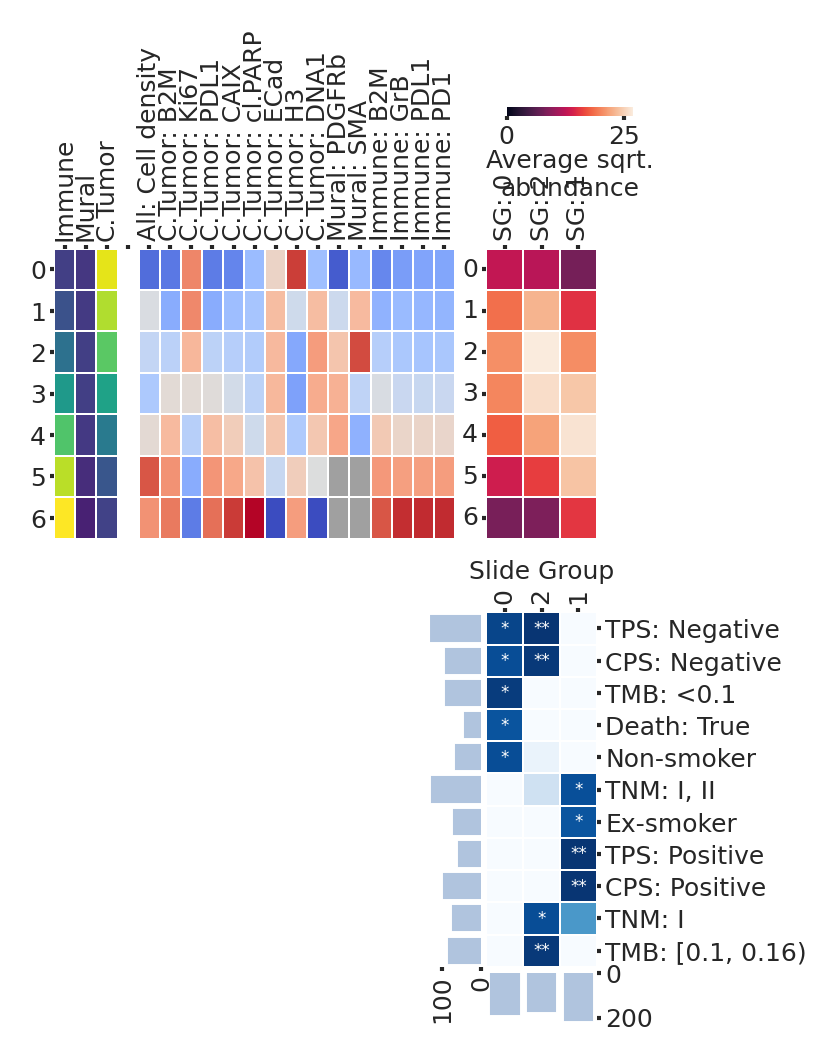

In [94]:
#matplotlib.rcParams['font.family'] = 'Arial'

table = big_l_clustering_df[CLUSTERS_TO_KEEP].T

tumor_percentage = -celltype_percentages['Tumor']
table_np = table
table_normalized = table_np / table_np.sum(axis=0)
tumor_average = (table_normalized.T * tumor_percentage.values).sum(axis=1)
table_normalized = table_np


big_l_figure = sns.clustermap(
    table_normalized.iloc[tumor_percentage.values.argsort(), tumor_average.argsort()],
    #row_cluster=False,
    figsize=(3.5, 4.1),
    linewidth=0.0035,
    row_colors=big_l_full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)],
    colors_ratio=(0.033, 0.04),
    xticklabels=True,
    yticklabels=list(range(CC_NB_OF_CLUSTERS)),
    row_cluster=False,
    col_cluster=False,
    vmin=0,
    cbar_pos=[0.58, 0.64, 0.12, 0.007],
    cbar_kws={'label': 'Norm.\nCN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)


big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()
big_l_figure.ax_heatmap.yaxis.tick_left()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_right()
big_l_figure.ax_row_colors.yaxis.tick_left()

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) for x in big_l_figure.data2d.columns],
    size=6,
)

big_l_figure.ax_row_colors.yaxis.set_tick_params(size=1, pad=1)
big_l_figure.ax_row_colors.set_yticks(
    ticks=[i + 0.5 for i in range(7)],
    labels=[i for i in range(7)],
    size=6,
)

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.06, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.03, row_box.y0, row_box.width, row_box.height])

# Create the counts barplot above col_colors
# Get the ordered counts based on the column order in the heatmap
permuted_rois = list(big_l_figure.data2d.columns)
ordered_counts = [sg_counts.loc[roi].values[0] for roi in permuted_rois]
ordered_counts_cl = clinical_counts_for_big_l.values[::-1, 0]


# Create a new axis for the barplot above col_colors
bar_height = 0.04  # Adjust this to change the height of the barplot
bar_height_cl = 0.05
bar_ax = big_l_figure.fig.add_axes([
    col_box.x0, 
    ax_col_colors.get_position().min[1] - bar_height - 0.005,  # Position above col_colors
    col_box.width, 
    bar_height
])

bar_ax_cl = big_l_figure.fig.add_axes([
    col_box.x0 - bar_height_cl - 0.005, 
    ax_col_colors.get_position().max[1] - col_box.height,  # Position above col_colors
    bar_height_cl,
    col_box.height
])

# Create the barplot
x_positions = list(range(len(ordered_counts)))
bars = bar_ax.bar(x_positions, ordered_counts, width=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax.invert_yaxis()
bar_ax.set_facecolor('white')

x_positions_cl = list(range(len(ordered_counts_cl)))
bars_cl = bar_ax_cl.barh(x_positions_cl, ordered_counts_cl, height=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax_cl.invert_xaxis()
bar_ax_cl.set_facecolor('white')


# Style the barplot
bar_ax.set_xlim(-0.5, len(ordered_counts) - 0.5)
bar_ax.set_xticks([])  # Remove x-axis ticks since they're shown below
bar_ax.spines['bottom'].set_visible(False)
bar_ax.spines['top'].set_visible(False)
bar_ax.spines['left'].set_linewidth(0.5)

# Style y-axis
bar_ax.tick_params(axis='y', labelsize=6, size=1, pad=1)
bar_ax.yaxis.tick_right()

bar_ax_cl.set_ylim(-0.5, len(ordered_counts_cl) - 0.5)
bar_ax_cl.set_yticks([])  # Remove x-axis ticks since they're shown below
bar_ax_cl.spines['top'].set_visible(False)
bar_ax_cl.spines['right'].set_visible(False)
bar_ax_cl.spines['left'].set_linewidth(0.5)

# Style y-axis
bar_ax_cl.tick_params(axis='x', labelsize=6, size=1, pad=1., rotation=90)

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)

big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Average sqrt.\nabundance', labelpad=0, size=6)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + .5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_col_colors.xaxis.set_label_position('top')

In [95]:
IMAGES_PATH_PANEL_1 = '/raid/immucan/IMC/NSCLC2/IMC1/unzipped/'
IMAGES_PATH_PANEL_2 = '/raid/immucan/IMC/NSCLC2_PANEL2/unzipped/' 

In [96]:
png_to_full_path = defaultdict(list)


for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_1):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))
            
            
for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_2):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))

In [97]:
import pyometiff

In [98]:
from pyometiff import OMETIFFReader

reader = OMETIFFReader(fpath=list(png_to_full_path.values())[0][0])

img_array, metadata, xml_metadata = reader.read()

In [99]:
cluster_sort = (-celltype_percentages['Tumor'].values).argsort()
CLUSTER_PERM = cluster_sort
CLUSTER_PERM_ARGSORT = numpy.argsort(CLUSTER_PERM)

cell_df['cc_perm'] = cell_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_PERM_ARGSORT[x])

In [100]:
SG_0_IMG_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'SG_0_IMG.tiff')
SG_0_IMAGE_NAME = 'IMMUcan_Batch20210921_LUNG_10041574-LUNG-VAR-TIS-01-IMC-01_002.tiff'

SG_2_IMG_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'SG_2_IMG.tiff')
SG_2_IMAGE_NAME = 'IMMUcan_Batch20210701_LUNG_10040796-LUNG-VAR-TIS-01-IMC-01_002.tiff'

SG_1_IMG_PATH = os.path.join(NSCLC_P1_PLDA_1_PATH, 'SG_1_IMG.tiff')
SG_1_IMAGE_NAME = 'IMMUcan_Batch20210701_LUNG_10040833-LUNG-VAR-TIS-01-IMC-01_001.tiff'

img_paths = [
    SG_0_IMG_PATH, SG_2_IMG_PATH, SG_1_IMG_PATH
]

img_names = [
    SG_0_IMAGE_NAME, SG_2_IMAGE_NAME, SG_1_IMAGE_NAME
]

NameError: name 'compute_triangle_areas' is not defined

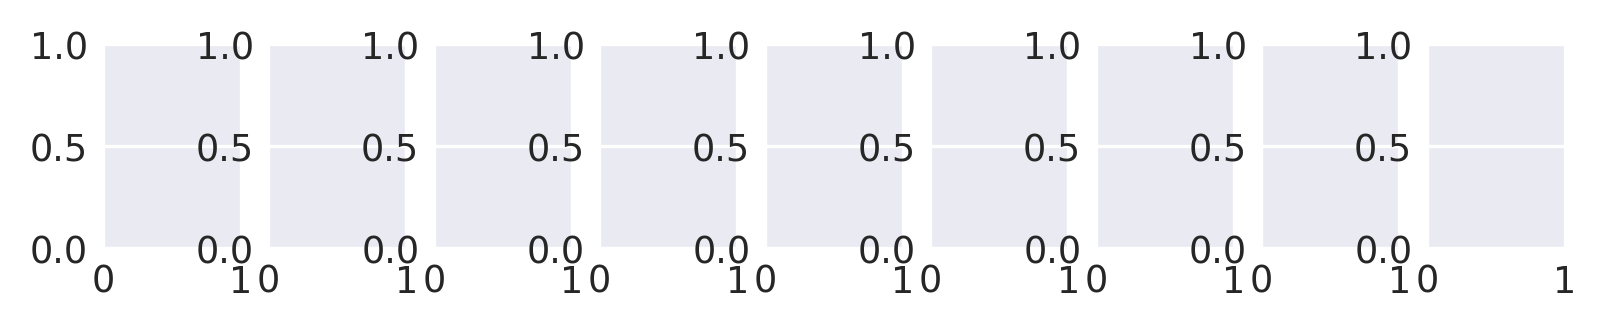

In [101]:
import matplotlib
from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable


tumor_percentage_argsort = (-class_percentages['C.Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image, image_path in zip(img_names, img_paths):
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(7, 1), dpi=300)
    gs = plt.GridSpec(2, 10, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 10)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=image_path)

    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('PLDA.1 CNs', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['cc_perm'],
        s=MARKER_SIZE,
        cmap='RdYlBu',
        linewidths=MARKER_SIZE,
        vmin=0,
        vmax=6,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap='RdYlBu')
    
    # Plot 3: ECAD Expression
    axs[2].set_title('ECAD', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('Ecad')
    image_m_arr = img_array[ECAD_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im2 = axs[2].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=2,
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('Ki67', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('Ki67')
    image_m_arr = img_array[KI67_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im3 = axs[3].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('PDGFRb', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('PDGFRb')
    image_m_arr = img_array[CD3_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im4 = axs[4].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[4].axis('off')
    
    axs[5].set_title('SMA', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('SMA')
    image_m_arr = img_array[CD3_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im5 = axs[5].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[5].axis('off')
    
    axs[6].set_title('CD3', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('CD3')
    image_m_arr = img_array[CD3_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im6 = axs[6].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[6].axis('off')
    
    axs[7].set_title('B2M', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('B2M')
    image_m_arr = img_array[CD3_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im7 = axs[7].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=2,
    )
    axs[7].axis('off')
    
    axs[8].set_title('PDL1', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('PDL1')
    image_m_arr = img_array[CD3_INDEX]
    image_m_arr = numpy.clip(image_m_arr, 0, numpy.quantile(image_m_arr, 0.95))
    im8 = axs[8].imshow(
        image_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[8].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4, im5, im6, im7, im8]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

In [ ]:
sd_c_min, sd_c_max = numpy.quantile(sd_df['0ss'], 0.05), numpy.quantile(sd_df['0ss'], 0.95)

In [ ]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()


corr_cmap = sns.clustermap(
    corr_df.iloc[tumor_percentage.argsort()].iloc[:, (tumor_percentage).argsort()],
    center=0,
    row_cluster=False,
    col_cluster=False,
    cmap='seismic',
    xticklabels=list(range(7)),
    yticklabels=list(range(7)),
    colors_ratio=0.1,
    figsize=(1., 1.),
    cbar_pos=[.9, 0.39, 0.02, 0.2],
    cbar_kws={'label': 'Pearson\nCorrelation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

hm_pos = corr_cmap.ax_heatmap.get_position()

BOX_WIDTH = 0.25
BOX_SPACE = 0.03

barplot_ax = corr_cmap.fig.add_axes([hm_pos.x0 - BOX_WIDTH - BOX_SPACE, hm_pos.y0, BOX_WIDTH, hm_pos.height], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    numpy.arange(7) + 0.5,
    cluster_counts.iloc[(tumor_percentage.argsort())],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Count', size=6, loc='left', labelpad=0.5)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)
barplot_ax.set_facecolor('white')

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)

corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=0)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
plt.gcf().get_size_inches()

corr_cmap.ax_heatmap.set_xlabel('Cellular\nNeighborhoods', labelpad=0.5)

In [ ]:
spatial_dimensions = pandas.read_csv(SD_PATH)

In [ ]:
spatial_dimensions = spatial_dimensions.set_index('Unnamed: 0')
spatial_dimensions = spatial_dimensions.loc[cell_df['Unnamed: 0']]

In [ ]:
import matplotlib.colors as mcolors

class_to_color = {
    'Immune': tau.META_CLUSTER_TO_COLOR['INFILTRATION'],
    'C.Tumor': tau.META_CLUSTER_TO_COLOR['PURE_TUMOR'], 
    'Other': mcolors.CSS4_COLORS['black'], 
    'Mural': tau.META_CLUSTER_TO_COLOR['MURAL']
}

In [ ]:
CLASSES_TO_PLOT = ['Immune', 'C.Tumor', 'Mural']

In [ ]:
plt.figure(figsize=(4, 4), dpi=300)
for class_ind, class_ in enumerate(CLASSES_TO_PLOT):
    plt.subplot(2, 2, class_ind + 1)
    plt.scatter(
        spatial_dimensions['2ss'][::100],
        spatial_dimensions['1ss'][::100],
        c=cell_df[::100]['Class'].apply(lambda x: class_to_color[x]),
        alpha=0.1 + 0.5 * (cell_df[::100]['Class'] == class_),
        s=1,
    )

In [ ]:
plt.figure(figsize=(6, 4), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(2, 3, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['Class'].apply(lambda x: class_to_color[x]),
            s=1,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

In [ ]:
histology_colors = {
    'Adenocarcinoma': '#2E86AB',           # Deep blue
    'Squamous cell carcinoma': '#A23B72',  # Maroon/burgundy
    'Other': '#708090',                     # Slate gray
    'Adenosquamous carcinoma': '#F18F01'    # Orange
}

In [ ]:
plt.figure(figsize=(6, 4), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(2, 3, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['sample_id'].apply(lambda x: tau.SIMPLE_HISTOLOGY_COLORS[
                roi_cluster_with_clinical.set_index(IMMUCAN_ID_COL).loc['-'.join(x.split('-')[:3])]['simple_histology']]),
            s=1,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

In [ ]:
plt.figure(figsize=(6, 4), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(2, 3, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['sample_id'].apply(lambda x: tau.SIMPLE_STAGE_COLORS[
                roi_cluster_with_clinical.set_index(IMMUCAN_ID_COL).loc['-'.join(x.split('-')[:3])]['simple_stage']]),
            s=1,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

In [ ]:
plt.figure(figsize=(6, 4), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(2, 3, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['sample_id'].apply(lambda x: 
                roi_cluster_with_clinical.set_index(IMMUCAN_ID_COL).loc['-'.join(x.split('-')[:3])]['CPS_score'] == 'positive'),
            s=1,
            cmap='magma',
            alpha=0.2,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

In [ ]:
plt.figure(figsize=(6, 4), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(2, 3, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df['CD20'][::100],
            s=1,
            #cmap='magma',
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()